# 01 · FUNCEME radar: raw scans → saved L1, L2 and L3

Run from top to bottom in your radar Python environment. This notebook starts with the **original scan NetCDFs** and creates `processed_data/l1_reflectivity`, `processed_data/l2_rainfall` and `processed_data/l3_rainfall` under your data drive. Notebook 02 reads these products independently.

| Product | Main variable | Grid | Time | Units |
|---|---|---|---|---|
| L1 | `reflectivity` | Fixed rectilinear geographic grid, nominal 800 m | Actual scan midpoint | dBZ |
| L2 | `rain_rate` | Same grid as L1 | Actual scan midpoint | mm h⁻¹ |
| L3 | `rain_rate`, `rainfall_amount` | 0.01° × 0.01° | Every 30 minutes, interval **start** | mm h⁻¹, mm per interval |

**Missingness contract:** within an existing scan, nonfinite reflectivity and values ≤ −100 become −100 dBZ inside the disk; corresponding L2 rainfall is exactly zero. Outside the disk, fields remain NaN. Entirely absent scans are **not** fabricated as dry observations. L3 retains every half hour, including missing days, with temporal coverage and scan counts.

**Provenance:** geographic remapping and scan-midpoint conventions come from `radar_vs_gauges.ipynb`. Its valid spatial convolution function is retained verbatim, now called at 0.01°. `pacha.calc_rate_from_refl` still performs the conversion, using its installed defaults and the existing export offset argument of 9. New orchestration, masks, metadata, gap handling and saving implement your requested changes.

The source notebooks do not establish native 800 m gates. The first-scan audit measures distances along both native coordinate axes. The target grid remains 800 m unless you change it after inspecting that audit. These are geographic rectangles with approximately 800 m spacing near the grid centre, not an exactly 800 m projected x/y lattice.

No real radar data have been processed in this delivered file. All execution outputs start empty.

## 1. Imports and configuration
Dependencies: your installed `pacha`, NumPy, pandas, xarray, Dask, SciPy, pyproj, netCDF4 and matplotlib. The companion notebook additionally uses geopandas/Shapely for optional catchments.

The paths and March–July 2023 dates follow the supplied notebooks. `START` and `END_EXCLUSIVE` are UTC day boundaries. Verify `SOURCE_TIMEZONE`: no timezone conversion is inferred from file location. The default nominal scan cadence is 5 minutes, consistent with the saved notebook output; the audit reports actual midpoint differences before processing. A period dominated by gaps may require manual cadence review.

The Z–R defaults are **read/verified at runtime**, not guessed here. `OVERWRITE=False` prevents accidental mixing with an earlier processing run. For a clean rerun use a fresh `PROCESSED_DIR` or explicitly enable overwrite. The optional original PCD parser can create gauge CSVs from raw files.

In [1]:
from pathlib import Path
from contextlib import ExitStack
from datetime import datetime, timezone
import hashlib
import inspect
import json
import os
import re
import unicodedata
import warnings
import numpy as np
import pandas as pd
import xarray as xr
import dask.array as da
from scipy.spatial import cKDTree, ConvexHull, Delaunay
from pyproj import CRS, Geod, Transformer
import matplotlib.pyplot as plt


In [ ]:
DATA_ROOT = Path('/media/admingosset/T7Shield/data')
RAW_DIR = DATA_ROOT / 'raw_data/ceara/ftp_evandro_2026'
# use processed_data folder
PROCESSED_DIR = Path('processed_data/')
L1_DIR = PROCESSED_DIR / 'l1_reflectivity'
L2_DIR = PROCESSED_DIR / 'l2_rainfall'
L3_DIR = PROCESSED_DIR / 'l3_rainfall'
START = pd.Timestamp('2024-01-01')
END_EXCLUSIVE = pd.Timestamp('2026-12-31')
SOURCE_TIMEZONE = 'UTC'  # Confirm archive convention; naive t_i/t_f are localized here.
RESOLUTION_M = 800.0    # Target spacing, NOT a claim about native gate spacing.
L3_DEGREES = 0.01
OFFSET_DB = 9.0         # Same argument as the original L2 export cell.
NO_ECHO_DBZ = -100.0
NOMINAL_SCAN_PERIOD = pd.Timedelta('5min')  # Used to cap temporal support; audit below.
MIN_TIME_COVERAGE = 0.90
MIN_SPATIAL_FRACTION = 0.01  # Valid disk overlap, not temporal availability.
GRID_ATOL_DEG = 1e-6
OVERWRITE = False
PARSE_RAW_GAUGES = False
GAUGE_RAW_DIR = DATA_ROOT / 'raw_data/ceara/pcds/pcds_funceme_eto_Dez_min'
GAUGE_COORDS_FILE = GAUGE_RAW_DIR / 'coordenadas_pcds.csv'


## 2. Inventory original scans
Filename dates are used only for a broad search margin. Authoritative times come from `t_i`/`t_f`; each scan is assigned their midpoint. A small halo around the requested period supports midnight L3 intervals. Unreadable files are listed in an audit table and contribute no temporal support; duplicate midpoints stop processing rather than silently double-counting.

In [4]:
def utc_naive(value):
    t = pd.Timestamp(value)
    if t.tzinfo is None:
        t = t.tz_localize(SOURCE_TIMEZONE)
    return t.tz_convert('UTC').tz_localize(None)


def scan_inventory(root, start, end):
    """Index scan metadata; preserve missing periods and reject duplicate midpoints."""
    rows, errors = [], []
    # A full-day filename margin accommodates scans crossing midnight.
    for path in sorted(Path(root).rglob('*.nc')):
        match = re.search(r'(\d{14})', path.name)
        if match:
            hint = utc_naive(pd.to_datetime(match.group(1), format='%Y%m%d%H%M%S'))
            if not start - pd.Timedelta('1D') <= hint < end + pd.Timedelta('1D'):
                continue
        try:
            with xr.open_dataset(path) as ds:
                ti, tf = utc_naive(ds.attrs['t_i']), utc_naive(ds.attrs['t_f'])
                if tf <= ti:
                    raise ValueError('t_f must be later than t_i')
                mid = ti + (tf - ti) / 2
                if start - NOMINAL_SCAN_PERIOD <= mid < end + NOMINAL_SCAN_PERIOD:
                    if 'dBZ' not in ds or 'xlon' not in ds or 'ylat' not in ds:
                        raise ValueError('Missing dBZ/xlon/ylat')
                    rows.append(dict(path=str(path), time=mid, scan_start=ti, scan_end=tf))
        except Exception as exc:
            errors.append(dict(path=str(path), error=repr(exc)))
    if not rows:
        raise ValueError(f'No readable scans in requested period. Errors: {errors[:3]}')
    frame = pd.DataFrame(rows).sort_values('time').reset_index(drop=True)
    duplicate = frame.time.duplicated(keep=False)
    if duplicate.any():
        raise ValueError('Duplicate scan midpoints; resolve duplicate files:\n' +
                         frame.loc[duplicate, ['time', 'path']].to_string(index=False))
    return frame, pd.DataFrame(errors, columns=['path', 'error'])


## 3. Inspect native spacing and construct a fixed grid
The existing nearest-gate method uses a KD-tree in a local metre projection and a convex hull of the native coordinates. The same mapping is reused only after each scan's coordinates pass a grid-equality check.

Native spacing statistics describe neighbouring gate centres along each array axis. They do not establish beam width or independently resolved pixel size. The convex hull preserves the outer disk approximately; it does not detect internal blocked sectors. The requested dry-fill policy applies inside this footprint, including missing echoes.

In [5]:
def native_spacing(ds):
    """Measured geodesic neighbour distances along both native array axes."""
    lon, lat = np.asarray(ds.xlon, float), np.asarray(ds.ylat, float)
    geod = Geod(ellps='WGS84')
    records = []
    for axis, dim in enumerate(ds.xlon.dims):
        left, right = [slice(None)] * 2, [slice(None)] * 2
        left[axis], right[axis] = slice(None, -1), slice(1, None)
        a, b = tuple(left), tuple(right)
        _, _, distance = geod.inv(lon[a], lat[a], lon[b], lat[b])
        valid = distance[np.isfinite(distance) & (distance > 0)]
        if not valid.size:
            raise ValueError(f'No valid neighbour spacing along {dim}')
        records.append(dict(native_dimension=dim, p05_m=np.percentile(valid, 5),
                            median_m=np.median(valid), p95_m=np.percentile(valid, 95),
                            minimum_m=valid.min(), maximum_m=valid.max()))
    return pd.DataFrame(records)


def build_mapping(ds, resolution_m=800):
    if not np.isfinite(resolution_m) or resolution_m <= 0:
        raise ValueError('resolution_m must be finite and positive')
    lon, lat = np.asarray(ds.xlon, float), np.asarray(ds.ylat, float)
    dims = ds.xlon.dims
    if lon.ndim != 2 or lat.shape != lon.shape or ds.ylat.dims != dims:
        raise ValueError('Expected matching static 2-D xlon and ylat')
    if not (np.isfinite(lon).all() and np.isfinite(lat).all()):
        raise ValueError('Coordinate holes require a separate footprint definition')
    lon0, lat0 = float(np.median(lon)), float(np.median(lat))
    geod = Geod(ellps='WGS84')
    _, _, dx = geod.inv(lon0, lat0, lon0 + .01, lat0)
    _, _, dy = geod.inv(lon0, lat0, lon0, lat0 + .01)
    dlon, dlat = resolution_m / (dx / .01), resolution_m / (dy / .01)
    out_lon = lon.min() + np.arange(int(np.ptp(lon) / dlon) + 1) * dlon
    out_lat = lat.min() + np.arange(int(np.ptp(lat) / dlat) + 1) * dlat
    if len(out_lon) * len(out_lat) > 25_000_000:
        raise ValueError('Output grid too large')
    projection = Transformer.from_crs('EPSG:4326', CRS.from_proj4(
        f'+proj=aeqd +lat_0={lat0} +lon_0={lon0} +datum=WGS84 +units=m'), always_xy=True)
    sx, sy = projection.transform(lon.ravel(), lat.ravel())
    source = np.column_stack([sx, sy])
    tlon, tlat = np.meshgrid(out_lon, out_lat)
    tx, ty = projection.transform(tlon.ravel(), tlat.ravel())
    target = np.column_stack([tx, ty])
    distance, nearest = cKDTree(source).query(target)
    hull = ConvexHull(source)
    footprint = Delaunay(source[hull.vertices])
    inside = footprint.find_simplex(target) >= 0
    return dict(source_lon=lon, source_lat=lat, dims=dims, lon=out_lon, lat=out_lat,
                nearest=nearest, inside=inside, projection=projection, footprint=footprint,
                distance=distance, resolution_m=float(resolution_m))


def verify_grid(ds, mapping):
    for key, name in [('source_lon', 'xlon'), ('source_lat', 'ylat')]:
        if ds[name].dims != mapping['dims'] or ds[name].shape != mapping[key].shape:
            raise ValueError('Native grid layout changed; process separately')
        if not np.allclose(ds[name].values, mapping[key], atol=GRID_ATOL_DEG, rtol=0):
            raise ValueError('Native geographic grid changed; refusing to reuse mapping')


def footprint_on_grid(mapping, lat, lon):
    lo, la = np.meshgrid(lon, lat)
    x, y = mapping['projection'].transform(lo.ravel(), la.ravel())
    return xr.DataArray((mapping['footprint'].find_simplex(np.c_[x, y]) >= 0)
                        .reshape(len(lat), len(lon)), dims=('lat', 'lon'),
                        coords={'lat': lat, 'lon': lon})


def to_lonlat(ds, resolution_m=800, variable='dBZ', mapping=None):
    """Existing nearest-gate approach, fixed grid, dry fill only inside the disk."""
    mapping = build_mapping(ds, resolution_m) if mapping is None else mapping
    verify_grid(ds, mapping)
    field = ds[variable].transpose('time', *mapping['dims']).astype('float32')
    data = field.chunk({'time': 1, **{dim: -1 for dim in mapping['dims']}}).data
    ny, nx = len(mapping['lat']), len(mapping['lon'])
    def remap(block):
        result = block.reshape(block.shape[0], -1)[:, mapping['nearest']].copy()
        # User policy: nonfinite/sentinel reflectivity inside an existing scan is dry.
        result[~np.isfinite(result) | (result <= NO_ECHO_DBZ)] = NO_ECHO_DBZ
        result[:, ~mapping['inside']] = np.nan
        return result.reshape(block.shape[0], ny, nx)
    values = da.map_blocks(remap, data, dtype=np.float32,
                          chunks=(data.chunks[0], (ny,), (nx,)), drop_axis=(1, 2),
                          new_axis=(1, 2), meta=np.empty((0, 0, 0), dtype=np.float32))
    return xr.Dataset({'reflectivity': (('time', 'lat', 'lon'), values),
                       'radar_mask': (('lat', 'lon'), mapping['inside'].reshape(ny, nx).astype('uint8'))},
                      coords={'time': ds.time, 'lat': mapping['lat'], 'lon': mapping['lon']})


## 4. Keep the installed rainfall conversion
The original notebook did not include the implementation of `calc_rate_from_refl`, nor explicit a/b values. Small probes of the installed function recover and verify its effective `Z = a R^b` relationship, prefer exact signature defaults when present, and measure whether its `offset=9` adds or subtracts dBZ. A non-power-law result stops with an explanatory error.

L2 uses that actual installed function. A no-echo sentinel is forced to **exactly zero rain**, independently of the numerical power law. Coefficients, offset argument, effective offset, signature and source hash are saved in the file attributes.

In [6]:
def rate_variable(result):
    if isinstance(result, xr.DataArray):
        return result
    for name in ('rain_rate', 'dBZ', 'reflectivity'):
        if name in result:
            return result[name]
    raise ValueError('Unexpected pacha result variables: ' + str(list(result.data_vars)))


def inspect_conversion(converter, offset):
    """Probe actual installed defaults; verify a power-law Z=a R**b response."""
    dbz = np.array([20., 30., 40.], dtype=np.float32)
    probe = xr.Dataset({'dBZ': (('time', 'lat', 'lon'), dbz[None, None, :])},
                       coords={'time': [np.datetime64('2000-01-01')], 'lat': [0.], 'lon': [0., .01, .02]})
    r0 = np.asarray(rate_variable(converter(probe.copy(deep=True), offset=0))).ravel()
    ro = np.asarray(rate_variable(converter(probe.copy(deep=True), offset=offset))).ravel()
    if not (np.isfinite(r0).all() and np.isfinite(ro).all() and (r0 > 0).all() and (ro > 0).all()):
        raise ValueError('Cannot identify conversion defaults: nonpositive or invalid probe rates')
    slope, intercept = np.polyfit(dbz, np.log10(r0), 1)
    b = 1 / (10 * slope)
    a = 10 ** (-b * intercept)
    if not np.allclose(r0, (10 ** (dbz / 10) / a) ** (1 / b), rtol=1e-4):
        raise ValueError('Installed conversion is not a single Z-R power law; inspect source')
    effective = 10 * b * np.log10(ro / r0)
    if not np.allclose(effective, effective.mean(), atol=1e-3):
        raise ValueError('Offset is not a constant dBZ correction; inspect source')
    sig = inspect.signature(converter)
    method = 'derived from zero-offset probes of installed pacha defaults'
    # Prefer exact declared coefficients when their numerical behavior matches the probes.
    defaults = {k.lower(): p.default for k, p in sig.parameters.items()
                if p.default is not inspect.Parameter.empty}
    if all(isinstance(defaults.get(k), (int, float)) for k in ('a', 'b')):
        aa, bb = float(defaults['a']), float(defaults['b'])
        if aa <= 0 or bb <= 0 or not np.allclose(r0, (10 ** (dbz / 10) / aa) ** (1 / bb), rtol=1e-4):
            raise ValueError('Declared a/b do not match probe rates')
        a, b, method = aa, bb, 'installed pacha signature defaults, verified by probes'
    try:
        code = inspect.getsource(converter)
    except (OSError, TypeError):
        code = repr(sig)
    return {'zr_a': float(a), 'zr_b': float(b), 'zr_parameters_source': method,
            'offset_argument_db': float(offset), 'effective_dbz_offset': float(effective.mean()),
            'rainfall_formula': 'R = (10**((reflectivity + effective_dbz_offset)/10) / zr_a)**(1/zr_b); no_echo -> 0',
            'conversion_function': converter.__module__ + '.' + converter.__name__,
            'conversion_signature': str(sig),
            'conversion_source_sha256': hashlib.sha256(code.encode()).hexdigest()}


def convert_l2(l1, converter, parameters):
    # Keep pacha's defaults and offset argument; never infer its sign from its name.
    probe_input = l1[['reflectivity']].rename({'reflectivity': 'dBZ'})
    converted = rate_variable(converter(probe_input.copy(deep=True), offset=parameters['offset_argument_db']))
    if set(converted.dims) != {'time', 'lat', 'lon'}:
        raise ValueError('Unexpected conversion dimensions')
    converted = converted.transpose('time', 'lat', 'lon')
    if not all(converted.sizes[d] == l1.sizes[d] and np.array_equal(converted[d], l1[d])
               for d in ('time', 'lat', 'lon')):
        raise ValueError('Conversion changed coordinates')
    rate = xr.where((l1.reflectivity <= NO_ECHO_DBZ) | ~np.isfinite(converted), 0, converted)
    rate = rate.clip(min=0).where(l1.radar_mask == 1).astype('float32')
    result = xr.Dataset({'rain_rate': rate, 'radar_mask': l1.radar_mask,
                         'scan_bounds': l1.scan_bounds})
    result.attrs = dict(l1.attrs, processing_level='L2', title='FUNCEME rainfall rate at native scan times',
                        **parameters)
    result.rain_rate.attrs = dict(long_name='Radar rainfall rate', units='mm h-1',
                                  no_echo_value=0., **parameters)
    result = coordinate_attrs(result)
    return result


## 5. Create native-time L1 and L2 files
One file per UTC day with observed scan midpoints only. `scan_bounds` preserves acquisition start/end. L1 reflectivity is uncorrected (offset applied = 0); its global attributes record the planned L2 conversion. Every product has units, geographic metadata, level, provenance and missing-value policy. NetCDF files are compressed and written via a temporary file.

In [7]:
def coordinate_attrs(ds):
    ds.lat.attrs.update(standard_name='latitude', units='degrees_north', axis='Y')
    ds.lon.attrs.update(standard_name='longitude', units='degrees_east', axis='X')
    ds.time.attrs.update(standard_name='time', axis='T', timezone='UTC')
    ds['crs'] = xr.DataArray(np.int32(0), attrs={'grid_mapping_name': 'latitude_longitude',
                         'semi_major_axis': 6378137., 'inverse_flattening': 298.257223563})
    for name in ds.data_vars:
        if {'lat', 'lon'}.issubset(ds[name].dims):
            ds[name].attrs['grid_mapping'] = 'crs'
    if 'radar_mask' in ds:
        ds.radar_mask.attrs.update(long_name='Radar disk based on convex hull of native gate centres',
                                  flag_values=np.array([0, 1], dtype='uint8'),
                                  flag_meanings='outside inside', units='1')
    return ds


def base_attrs(level, rows, mapping, fingerprint):
    return dict(Conventions='CF-1.8', institution='FUNCEME', source='FUNCEME native radar NetCDF scans',
                title=f'FUNCEME radar {level}', processing_level=level,
                history=f'{datetime.now(timezone.utc).isoformat()}: processed from raw scans',
                processing_config_sha256=fingerprint, source_file_count=len(rows),
                source_files=json.dumps([Path(p).name for p in rows.path]),
                nominal_grid_spacing_m=mapping['resolution_m'],
                grid_description='Rectilinear geographic lat/lon grid; approximately stated metres near grid centre',
                geospatial_lat_min=float(mapping['lat'][0]), geospatial_lat_max=float(mapping['lat'][-1]),
                geospatial_lon_min=float(mapping['lon'][0]), geospatial_lon_max=float(mapping['lon'][-1]),
                regridding='nearest native gate in local azimuthal equidistant projection',
                footprint_method='convex hull of static native gate centres',
                inside_missing_policy='existing scan: nonfinite/<=-100 dBZ -> -100 dBZ -> 0 mm h-1',
                outside_missing_policy='NaN outside radar disk',
                absent_scan_policy='no fabricated L1/L2 observations; L3 time gaps retained and coverage recorded',
                time_convention='UTC; native scan midpoint',
                time_coverage_start=str(rows.scan_start.min()), time_coverage_end=str(rows.scan_end.max()))


def write_netcdf(ds, path):
    path = Path(path)
    if path.exists() and not OVERWRITE:
        raise FileExistsError(f'{path} exists; set OVERWRITE=True for a deliberate rerun')
    temporary = path.with_suffix('.tmp.nc')
    encoding = {}
    for name, var in ds.variables.items():
        if name in ds.data_vars and var.dtype.kind == 'f':
            encoding[name] = {'zlib': True, 'complevel': 4, 'dtype': 'float32', '_FillValue': np.float32(np.nan)}
            if var.dims == ('time', 'lat', 'lon'):
                encoding[name]['chunksizes'] = (1, min(256, var.sizes['lat']), min(256, var.sizes['lon']))
        elif name in ds.data_vars and var.dtype.kind in 'iu':
            encoding[name] = {'zlib': True, 'complevel': 4, '_FillValue': None}
        if np.issubdtype(var.dtype, np.datetime64):
            encoding[name] = {'units': 'seconds since 1970-01-01 00:00:00',
                              'calendar': 'proleptic_gregorian', 'dtype': 'float64', '_FillValue': None}
    try:
        ds.to_netcdf(temporary, engine='netcdf4', encoding=encoding)
        os.replace(temporary, path)
    finally:
        temporary.unlink(missing_ok=True)


def process_native_day(rows, mapping, converter, parameters, fingerprint):
    with ExitStack() as stack:
        scans = []
        for row in rows.itertuples():
            raw = stack.enter_context(xr.open_dataset(row.path, chunks={}))
            verify_grid(raw, mapping)
            if set(raw.dBZ.dims) != set(mapping['dims']):
                raise ValueError('Expected one native 2-D scan per file')
            # Discard repeated 2-D coordinates after validation; fixed mapping holds them.
            field = raw.dBZ.transpose(*mapping['dims']).reset_coords(drop=True)
            scans.append(field.expand_dims(time=[row.time.to_datetime64()]))
        joined = xr.concat(scans, dim='time', join='exact', coords='minimal', compat='equals').to_dataset(name='dBZ')
        joined = joined.assign_coords(xlon=(mapping['dims'], mapping['source_lon']),
                                      ylat=(mapping['dims'], mapping['source_lat']))
        l1 = to_lonlat(joined, mapping=mapping)
        l1['scan_bounds'] = (('time', 'bounds'), rows[['scan_start', 'scan_end']].to_numpy(dtype='datetime64[ns]'))
        l1.time.attrs['bounds'] = 'scan_bounds'
        l1.reflectivity.attrs = dict(long_name='Uncorrected radar reflectivity factor', units='dBZ',
                                    no_echo_value=NO_ECHO_DBZ, reflectivity_offset_applied_db=0.)
        l1.attrs = base_attrs('L1', rows, mapping, fingerprint)
        l1.attrs.update({f'planned_l2_{key}': value for key, value in parameters.items()})
        for key in ('radar', 'Instituicao', 'descricao'):
            if key in raw.attrs:
                l1.attrs[f'source_{key}'] = str(raw.attrs[key])
        l1 = coordinate_attrs(l1)
        day = pd.Timestamp(rows.time.iloc[0]).strftime('%Y-%m-%d')
        write_netcdf(l1, L1_DIR / f'l1_reflectivity_{day}.nc')
        l2 = convert_l2(l1, converter, parameters)
        write_netcdf(l2, L2_DIR / f'l2_rainfall_{day}.nc')


## 6. Original spatial averaging function
This is the valid function cell from `radar_vs_gauges.ipynb`, retained unchanged. The corrupted copy in `extract_rain_shps_retooled.ipynb` is not used. L3 calls this function with `resolution=0.01`; its original default remains 0.1 for provenance.

In [8]:
"""Spatial averaging of regularly gridded lat/lon radar fields onto an aligned coarser grid."""

import numpy as np
import xarray as xr
from scipy.ndimage import convolve1d


def _infer_grid_step(values, name):
    """Return native step in degrees after validating a regular, monotonic 1-D axis."""
    values = np.asarray(values, dtype=np.float64)
    if values.ndim != 1 or values.size < 2 or not np.all(np.isfinite(values)):
        raise ValueError(f"'{name}' must be a 1-D numeric coordinate with >=2 finite values")
    differences = np.diff(values)
    if not (np.all(differences > 0) or np.all(differences < 0)):
        raise ValueError(f"'{name}' must be strictly monotonic")
    step = float(np.median(np.abs(differences)))
    if not np.allclose(np.abs(differences), step, rtol=0.01, atol=1e-10):
        raise ValueError(f"'{name}' must be regularly spaced (within 1%)")
    return step


def _target_centers(values, step):
    """Global 0.5*step-offset centers with entire output footprint within source coords."""
    lo, hi = float(np.min(values)), float(np.max(values))
    # Centers are (k + 0.5)*step and their edges are k*step, (k+1)*step.
    # Require those two edges to stay within [lo, hi].
    eps = 1e-10
    k_first = int(np.ceil(lo / step - eps))
    k_last = int(np.floor(hi / step - 1 + eps))
    if k_last < k_first:
        raise ValueError(f"Source domain [{lo}, {hi}] cannot fit a full {step:g}° output cell")
    return (np.arange(k_first, k_last + 1, dtype=np.int64) + 0.5) * step


def _box_weights(width_in_source_pixels):
    """Normalized symmetric weights accounting for partially covered edge pixels."""
    half_width = width_in_source_pixels / 2.0
    radius = int(np.ceil(half_width + 0.5))
    offsets = np.arange(-radius, radius + 1, dtype=np.float64)
    overlap = np.maximum(
        0.0,
        np.minimum(offsets + 0.5, half_width)
        - np.maximum(offsets - 0.5, -half_width),
    )
    overlap = overlap[overlap > 1e-12]
    return overlap / overlap.sum()


def _mean_filter_2d(arr, w_lat, w_lon, min_valid_fraction):
    """Separable NaN-aware box convolution for one (lat, lon) frame."""
    valid = np.isfinite(arr)
    cleaned = np.where(valid, arr, 0).astype(np.float64, copy=False)
    weights = valid.astype(np.float64)

    for axis, kernel in ((0, w_lat), (1, w_lon)):
        cleaned = convolve1d(cleaned, kernel, axis=axis, mode="constant", cval=0.0)
        weights = convolve1d(weights, kernel, axis=axis, mode="constant", cval=0.0)

    result = np.full(cleaned.shape, np.nan, dtype=np.float64)
    np.divide(
        cleaned,
        weights,
        out=result,
        where=(weights > 0) & (weights >= min_valid_fraction - 1e-10),
    )
    return result


def spatial_average_resample(data, resolution=0.1, *, min_valid_fraction=0.8,
                             method="linear"):
    """Spatially average a regular lat/lon DataArray or Dataset on a new grid.

    Parameters
    ----------
    data : xr.DataArray or xr.Dataset
        Fields with 1-D 'lat' and 'lon' coordinates. Extra dims, e.g. time,
        are preserved. Dataset variables with both lat/lon are averaged;
        variables without either dimension are copied unchanged.
    resolution : float or (lat_step, lon_step)
        Target grid spacing in degrees, e.g. 0.1 or (0.1, 0.1).
        Output centers are aligned to (..., -0.05, 0.05, 0.15, ...)
        for resolution=0.1, excluding cells whose *edges* lie outside
        the primary coordinates.
    min_valid_fraction : float, default 0.8
        Minimum fraction of the convolution footprint having finite data.
        The mean is calculated using valid cells only; set 1.0 to demand
        complete coverage.
    method : {'linear', 'nearest'}, default 'linear'
        Sampling of the smoothed radar field at output cell centers.
        'nearest' more closely reproduces the original notebook method;
        'linear' better handles offset between source and target centers.

    Returns
    -------
    xr.DataArray or xr.Dataset
        Spatially averaged data on the newly built regular output grid.
        Spatial coordinates are ascending; no disk output is written.

    Notes
    -----
    This approximates cell averages using a symmetric box convolution before
    resampling; it is not exact conservative area-overlap remapping.
    Coordinates must be rectilinear longitude/latitude in degrees.
    """
    if not isinstance(data, (xr.DataArray, xr.Dataset)):
        raise TypeError("data must be an xarray DataArray or Dataset")
    if 'lat' not in data.dims or 'lon' not in data.dims:
        raise ValueError("data must have 'lat' and 'lon' dimensions")
    for coord in ('lat', 'lon'):
        if coord not in data.coords or data[coord].dims != (coord,):
            raise ValueError(f"'{coord}' must be a 1-D dimension coordinate")
    if np.isscalar(resolution):
        target_lat_step = target_lon_step = float(resolution)
    else:
        if len(resolution) != 2:
            raise ValueError("resolution must be one number or (lat_step, lon_step)")
        target_lat_step, target_lon_step = map(float, resolution)
    if not all(np.isfinite([target_lat_step, target_lon_step])) or min(target_lat_step, target_lon_step) <= 0:
        raise ValueError("resolution must be strictly positive and finite")
    if not 0 < min_valid_fraction <= 1:
        raise ValueError("min_valid_fraction must be in (0, 1]")
    if method not in ('linear', 'nearest'):
        raise ValueError("method must be 'linear' or 'nearest'")

    src_lat_step = _infer_grid_step(data.lat.values, 'lat')
    src_lon_step = _infer_grid_step(data.lon.values, 'lon')
    if target_lat_step < src_lat_step * (1 - 1e-8) or target_lon_step < src_lon_step * (1 - 1e-8):
        raise ValueError("Output resolution must be coarser than or equal to both input steps")

    new_lat = _target_centers(data.lat.values, target_lat_step)
    new_lon = _target_centers(data.lon.values, target_lon_step)
    w_lat = _box_weights(target_lat_step / src_lat_step)
    w_lon = _box_weights(target_lon_step / src_lon_step)

    data = data.sortby('lat').sortby('lon')

    def apply_to_da(da):
        if not {'lat', 'lon'}.issubset(da.dims):
            if {'lat', 'lon'} & set(da.dims):
                raise ValueError(f"Variable {da.name!r} has only one spatial dimension")
            return da.copy()
        if not np.issubdtype(da.dtype, np.number):
            raise TypeError(f"Variable {da.name!r} must contain numerical data")
        smoothed = xr.apply_ufunc(
            _mean_filter_2d,
            da,
            input_core_dims=[['lat', 'lon']],
            output_core_dims=[['lat', 'lon']],
            kwargs={'w_lat': w_lat, 'w_lon': w_lon,
                    'min_valid_fraction': min_valid_fraction},
            vectorize=True,
            dask='parallelized',
            dask_gufunc_kwargs={'allow_rechunk': True},
            output_dtypes=[np.float64],
            keep_attrs=True,
        )
        return smoothed.interp(lat=new_lat, lon=new_lon, method=method)

    if isinstance(data, xr.DataArray):
        result = apply_to_da(data)
    else:
        result = xr.Dataset(
            {name: apply_to_da(da) for name, da in data.data_vars.items()},
            attrs=data.attrs.copy(),
        )

    result.attrs.update({
        'spatial_resampling': 'NaN-aware box convolution then ' + method + ' sampling',
        'source_lat_step_degrees': src_lat_step,
        'source_lon_step_degrees': src_lon_step,
        'target_lat_step_degrees': target_lat_step,
        'target_lon_step_degrees': target_lon_step,
        'spatial_kernel_size': f'{len(w_lat)}x{len(w_lon)}',
    })
    return result

## 7. L3 temporal integration and disk-preserving spatial resampling
Each midpoint represents at most one nominal scan period: ±2.5 minutes at the default cadence, clipped at neighbour midpoint boundaries to prevent double counting. Missing scans therefore leave uncovered time. This is an explicit temporal representation assumption; scan acquisition duration is preserved separately and is not mistaken for the whole sampling period.

The original convolution/resampling is applied to rainfall. A separately averaged disk mask normalizes spatial support near the disk edge, then the target-centre footprint mask is reapplied. `spatial_coverage` records this approximate footprint fraction. This is the original box-filter approximation, not conservative area-overlap regridding.

Each L3 day has 48 timestamps: `00:00, 00:30, …, 23:30`. `time_bounds` records `[start, start+30min)`. Neighbouring days supply boundary scans.

- `rainfall_observed` integrates only the supported portions of each interval; no observations → NaN.
- `temporal_coverage` is supported seconds / 1800. It does not measure pixel-quality coverage: pixel NaNs follow your dry-fill policy.
- `rain_rate` is the observed weighted mean, masked below 90% temporal coverage by default.
- `rainfall_amount = rain_rate × 0.5 h` estimates the full interval for accepted bins. At coverage below 100%, this normalizes the small gap; the observed subtotal is retained separately. Set `MIN_TIME_COVERAGE=1.0` to require complete modeled support.

Outside-disk rainfall is always NaN. Whole missing days still get a file containing 48 missing rainfall fields and zero temporal coverage.

In [9]:
def temporal_weights(times, day, cadence):
    """Overlap seconds for 48 left-labeled half hours; support capped at one cadence.

    Each midpoint represents +/- cadence/2. Neighbour midpoints clip the support
    to prevent overlap. Missing scans leave uncovered time instead of zeros.
    """
    times = pd.DatetimeIndex(times)
    if not times.is_monotonic_increasing or times.has_duplicates:
        raise ValueError('Scan midpoints must be unique and sorted')
    seconds = times.asi8.astype(np.float64) / 1e9
    half = cadence.total_seconds() / 2
    left, right = seconds - half, seconds + half
    if len(seconds) > 1:
        splits = (seconds[1:] + seconds[:-1]) / 2
        left[1:] = np.maximum(left[1:], splits)
        right[:-1] = np.minimum(right[:-1], splits)
    edges = pd.date_range(day, periods=49, freq='30min')
    edge_seconds = edges.asi8.astype(np.float64) / 1e9
    weights = np.maximum(0, np.minimum(edge_seconds[1:, None], right) -
                         np.maximum(edge_seconds[:-1, None], left))
    labels = edges[:-1]
    return weights, labels, np.column_stack([edges[:-1].values, edges[1:].values])


def make_l3(native_rate, mapping, day, parameters, fingerprint):
    # Coarsen the existing Cartesian grid using the ORIGINAL notebook function.
    # Normalize disk-edge spatial support separately; never interpolate an exterior zero.
    disk = xr.DataArray(mapping['inside'].reshape(len(mapping['lat']), len(mapping['lon'])),
                        dims=('lat', 'lon'), coords={'lat': mapping['lat'], 'lon': mapping['lon']})
    # Spatial averaging of a 0/1 mask gives a footprint fraction.
    support = spatial_average_resample(disk.astype('float32'), resolution=L3_DEGREES,
                                       min_valid_fraction=1e-6, method='linear')
    mask = footprint_on_grid(mapping, support.lat.values, support.lon.values)
    spatial_ok = mask & (support >= MIN_SPATIAL_FRACTION)
    labels = pd.date_range(day, periods=48, freq='30min')
    bounds = np.column_stack([labels.values, (labels + pd.Timedelta('30min')).values])
    if native_rate is not None and native_rate.sizes['time']:
        weights, labels, bounds = temporal_weights(native_rate.time.values, day, NOMINAL_SCAN_PERIOD)
        w = xr.DataArray(weights, dims=('interval', 'time'),
                         coords={'interval': labels, 'time': native_rate.time})
        seconds = w.sum('time')
        covered_fraction = (seconds / 1800).clip(0, 1)
        # Existing scans are finite everywhere inside the disk; exterior zeros here
        # are only algebraic numerator padding, removed by support normalization/mask.
        numerator = spatial_average_resample(native_rate.fillna(0), resolution=L3_DEGREES,
                                              min_valid_fraction=1e-6, method='linear')
        coarse = (numerator / support.where(support > 0)).where(spatial_ok)
        observed = xr.dot(w, coarse.fillna(0), dim='time') / 3600
        observed = observed.rename(interval='time').transpose('time', 'lat', 'lon')
        seconds = seconds.rename(interval='time')
        coverage = covered_fraction.rename(interval='time')
        observed = observed.where((seconds > 0) & spatial_ok)
        mean_rate = (observed / (seconds / 3600).where(seconds > 0)).where(coverage >= MIN_TIME_COVERAGE)
        count = ((weights > 0).sum(axis=1)).astype('int32')
    else:
        observed = xr.DataArray(np.full((48, len(support.lat), len(support.lon)), np.nan, dtype='float32'),
                                dims=('time', 'lat', 'lon'),
                                coords={'time': labels, 'lat': support.lat, 'lon': support.lon})
        mean_rate = observed.copy()
        coverage = xr.DataArray(np.zeros(48, dtype='float32'), dims='time', coords={'time': labels})
        count = np.zeros(48, dtype='int32')
    result = xr.Dataset({'rain_rate': mean_rate.astype('float32'),
                         'rainfall_amount': (mean_rate * .5).astype('float32'),
                         'rainfall_observed': observed.astype('float32'),
                         'temporal_coverage': coverage.astype('float32'),
                         'scan_count': ('time', count), 'radar_mask': mask.astype('uint8'),
                         'spatial_coverage': support.where(mask).astype('float32'),
                         'time_bounds': (('time', 'bounds'), bounds)})
    result.attrs = dict(Conventions='CF-1.8', institution='FUNCEME', processing_level='L3',
        title='FUNCEME rainfall on 0.01 degree grid and 30-minute intervals',
        history=f'{datetime.now(timezone.utc).isoformat()}: L2 spatial averaging and temporal integration',
        processing_config_sha256=fingerprint,
        spatial_resampling='Original NaN-aware box convolution + linear sampling; disk-edge support normalized',
        spatial_resolution_degrees=L3_DEGREES, source_nominal_grid_spacing_m=RESOLUTION_M,
        minimum_temporal_coverage=MIN_TIME_COVERAGE, minimum_spatial_fraction=MIN_SPATIAL_FRACTION,
        temporal_support='midpoint +/- nominal cadence/2, clipped at neighbour midpoint boundaries',
        nominal_scan_period_seconds=NOMINAL_SCAN_PERIOD.total_seconds(),
        time_convention='UTC; time labels the start of [time, time+30min)',
        rainfall_amount_method='coverage-qualified observed mean rate multiplied by 0.5 hours; small gaps normalized',
        rainfall_observed_method='integral over supported time only; NaN when no temporal support',
        missing_policy='absent scans never become zero; low-coverage bins masked; outside disk NaN',
        time_coverage_start=str(pd.Timestamp(day)), time_coverage_end=str(pd.Timestamp(day)+pd.Timedelta('1D')),
        **parameters)
    result.time.attrs.update(bounds='time_bounds', long_name='Start of 30-minute interval')
    for name, units, long_name, method in [
        ('rain_rate','mm h-1','Mean rainfall rate over supported time; coverage-qualified','time: mean'),
        ('rainfall_amount','mm','Estimated rainfall depth for 30-minute interval; coverage-qualified','time: sum'),
        ('rainfall_observed','mm','Rainfall depth integrated over observed temporal support only','time: sum')]:
        result[name].attrs.update(units=units,long_name=long_name,cell_methods=method, **parameters)
    result.temporal_coverage.attrs.update(units='1',valid_min=0.,valid_max=1.,
        long_name='Fraction of the 30-minute interval supported by available scans')
    result.spatial_coverage.attrs.update(units='1',long_name='Approximate fraction of spatial averaging footprint inside source disk')
    result.scan_count.attrs.update(units='1',long_name='Number of scans contributing temporal support to interval')
    return coordinate_attrs(result)


def process_l3_day(day, mapping, parameters, fingerprint):
    paths = [L2_DIR / f'l2_rainfall_{d:%Y-%m-%d}.nc'
             for d in pd.date_range(day-pd.Timedelta('1D'), day+pd.Timedelta('1D'))]
    with ExitStack() as stack:
        arrays = []
        for path in paths:
            if path.exists():
                ds = stack.enter_context(xr.open_dataset(path, chunks={'time': 1}))
                if ds.attrs.get('processing_config_sha256') != fingerprint:
                    raise ValueError(f'Incompatible previous product: {path}')
                selected = ds.rain_rate.sel(time=slice(day-NOMINAL_SCAN_PERIOD,
                                  day+pd.Timedelta('1D')+NOMINAL_SCAN_PERIOD))
                if selected.sizes['time']:
                    arrays.append(selected)
        rate = xr.concat(arrays, dim='time', join='exact').sortby('time') if arrays else None
        out = make_l3(rate, mapping, day, parameters, fingerprint)
        write_netcdf(out, L3_DIR / f'l3_rainfall_{day:%Y-%m-%d}.nc')


## Initialize folders and settings

In [10]:
if START != START.normalize() or END_EXCLUSIVE != END_EXCLUSIVE.normalize() or END_EXCLUSIVE <= START:
    raise ValueError('Use increasing UTC midnight START and END_EXCLUSIVE values')
if not RAW_DIR.is_dir():
    raise FileNotFoundError(f'Raw radar directory not found: {RAW_DIR}')
if NOMINAL_SCAN_PERIOD <= pd.Timedelta(0) or not 0 < MIN_TIME_COVERAGE <= 1:
    raise ValueError('Invalid temporal coverage configuration')
for directory in (PROCESSED_DIR, L1_DIR, L2_DIR, L3_DIR):
    directory.mkdir(parents=True, exist_ok=True)
print('Output root:', PROCESSED_DIR)


Output root: processed_data


## Read installed conversion and record actual parameters

In [11]:
from pacha.L2_processing import radar as l2rad
conversion_parameters = inspect_conversion(l2rad.calc_rate_from_refl, OFFSET_DB)
display(pd.Series(conversion_parameters, name='actual_conversion_settings'))


zr_a                                                                    200.0
zr_b                                                                      1.6
zr_parameters_source        installed pacha signature defaults, verified b...
offset_argument_db                                                        9.0
effective_dbz_offset                                                 9.000001
rainfall_formula            R = (10**((reflectivity + effective_dbz_offset...
conversion_function             pacha.L2_processing.radar.calc_rate_from_refl
conversion_signature                         (ref, a=200, b=1.6, offset=None)
conversion_source_sha256    f506c98d52a55f49d9511e00f18a8c79a24731345f42c6...
Name: actual_conversion_settings, dtype: object

## Inventory and grid audit

,native_dimension,p05_m,median_m,p95_m,minimum_m,maximum_m
0,i,245.299635,2440.316307,4630.983446,4.601008,4887.988904
1,j,372.143821,373.483847,374.861009,371.651692,375.350538


Native array dimensions are reported by name; do not assume i=range or j=azimuth.
Observed scan-midpoint spacing, seconds:


count     20164.000000
mean        430.849683
std        5893.011715
min         187.000000
5%          298.000000
50%         300.000000
95%         534.000000
max      777899.000000
Name: time, dtype: float64

Nominal temporal support cap: 0 days 00:05:00
Nearest-gate distance on the 800 m target grid [p50,p95,max] m: [ 723.3 1893.  2439.9]


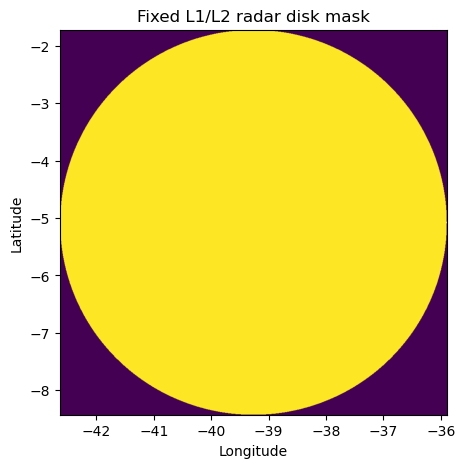

In [12]:
inventory, inventory_errors = scan_inventory(RAW_DIR, START, END_EXCLUSIVE)
if not inventory_errors.empty:
    display(inventory_errors)
    print('Unreadable files are excluded; their missing temporal support remains missing.')
with xr.open_dataset(inventory.path.iloc[0]) as reference:
    mapping = build_mapping(reference, RESOLUTION_M)
    spacing_report = native_spacing(reference)
    reference_attrs = dict(reference.attrs)
display(spacing_report)
print('Native array dimensions are reported by name; do not assume i=range or j=azimuth.')
delta = inventory.time.diff().dt.total_seconds().dropna()
print('Observed scan-midpoint spacing, seconds:')
display(delta.describe(percentiles=[.05,.5,.95]))
print('Nominal temporal support cap:', NOMINAL_SCAN_PERIOD)
if not delta.empty and abs(delta.median()-NOMINAL_SCAN_PERIOD.total_seconds()) > 0.2*NOMINAL_SCAN_PERIOD.total_seconds():
    raise ValueError('Median cadence differs from NOMINAL_SCAN_PERIOD by >20%; inspect gaps and update configuration')
finite_distances = mapping['distance'][mapping['inside']]
print('Nearest-gate distance on the 800 m target grid [p50,p95,max] m:',
      np.percentile(finite_distances, [50,95,100]).round(1))
fig, ax = plt.subplots(figsize=(8,5))
ax.imshow(mapping['inside'].reshape(len(mapping['lat']),len(mapping['lon'])), origin='lower',
          extent=[mapping['lon'][0],mapping['lon'][-1],mapping['lat'][0],mapping['lat'][-1]])
ax.set(xlabel='Longitude',ylabel='Latitude',title='Fixed L1/L2 radar disk mask')
plt.show()


## Persist inventory and run configuration; prevent mixing runs

In [13]:
run_config = dict(start=str(START), end_exclusive=str(END_EXCLUSIVE), raw_dir=str(RAW_DIR),
    source_timezone=SOURCE_TIMEZONE, resolution_m=RESOLUTION_M, l3_degrees=L3_DEGREES,
    offset_db=OFFSET_DB, no_echo_dbz=NO_ECHO_DBZ,
    nominal_scan_period_seconds=NOMINAL_SCAN_PERIOD.total_seconds(),
    minimum_time_coverage=MIN_TIME_COVERAGE, minimum_spatial_fraction=MIN_SPATIAL_FRACTION,
    time_label='start', conversion=conversion_parameters,
    reference_radar_attributes={k:str(v) for k,v in reference_attrs.items()},
    native_spacing=spacing_report.to_dict(orient='records'),
    source_grid_sha256=hashlib.sha256(mapping['source_lon'].tobytes()+mapping['source_lat'].tobytes()).hexdigest(),
    inventory_sha256=hashlib.sha256(inventory.to_csv(index=False).encode()).hexdigest(),
    inventory_error_count=len(inventory_errors))
fingerprint = hashlib.sha256(json.dumps(run_config,sort_keys=True).encode()).hexdigest()
run_config['processing_config_sha256'] = fingerprint
config_path = PROCESSED_DIR / 'run_config.json'
existing_products = [p for directory in (L1_DIR,L2_DIR,L3_DIR) for p in directory.glob('*.nc')]
if existing_products and not OVERWRITE:
    raise FileExistsError('Processed products already exist. Use a new PROCESSED_DIR or deliberately set OVERWRITE=True.')
config_path.write_text(json.dumps(run_config,indent=2))
inventory.to_csv(PROCESSED_DIR/'raw_scan_inventory.csv',index=False)
inventory_errors.to_csv(PROCESSED_DIR/'raw_scan_errors.csv',index=False)
spacing_report.to_csv(PROCESSED_DIR/'native_gate_spacing.csv',index=False)
print('Saved settings and audit tables. Native scans available:',len(inventory))


Saved settings and audit tables. Native scans available: 20165


## Process and save daily L1/L2 from the original scans

In [14]:
# A one-cadence halo may create an adjacent-day L1/L2 file for L3 boundary support.
manifest_rows = []
for day, rows in inventory.groupby(inventory.time.dt.floor('D'), sort=True):
    print('L1/L2', day.date(), 'scans:',len(rows))
    process_native_day(rows, mapping, l2rad.calc_rate_from_refl, conversion_parameters, fingerprint)
    manifest_rows.append(dict(day=str(day.date()),native_scan_count=len(rows),status='L1/L2 written'))
    pd.DataFrame(manifest_rows).to_csv(PROCESSED_DIR/'processing_manifest.csv',index=False)


L1/L2 2023-04-01 scans: 161
L1/L2 2023-04-02 scans: 162
L1/L2 2023-04-03 scans: 164
L1/L2 2023-04-04 scans: 162
L1/L2 2023-04-05 scans: 142
L1/L2 2023-04-06 scans: 162
L1/L2 2023-04-07 scans: 162
L1/L2 2023-04-08 scans: 162
L1/L2 2023-04-09 scans: 162
L1/L2 2023-04-10 scans: 162
L1/L2 2023-04-11 scans: 161
L1/L2 2023-04-12 scans: 155
L1/L2 2023-04-13 scans: 162
L1/L2 2023-04-14 scans: 162
L1/L2 2023-04-15 scans: 157
L1/L2 2023-04-16 scans: 162
L1/L2 2023-04-17 scans: 244
L1/L2 2023-04-18 scans: 55
L1/L2 2023-04-19 scans: 228
L1/L2 2023-04-20 scans: 259
L1/L2 2023-04-21 scans: 140
L1/L2 2023-04-22 scans: 288
L1/L2 2023-04-23 scans: 288
L1/L2 2023-04-24 scans: 226
L1/L2 2023-04-25 scans: 275
L1/L2 2023-04-26 scans: 288
L1/L2 2023-04-27 scans: 288
L1/L2 2023-04-28 scans: 240
L1/L2 2023-04-29 scans: 159
L1/L2 2023-04-30 scans: 288
L1/L2 2023-05-10 scans: 288
L1/L2 2023-05-11 scans: 288
L1/L2 2023-05-12 scans: 288
L1/L2 2023-05-13 scans: 282
L1/L2 2023-05-14 scans: 287
L1/L2 2023-05-15 scan

## Process and save every half hour, including entirely missing days

In [15]:
for day in pd.date_range(START,END_EXCLUSIVE-pd.Timedelta('1D'),freq='D'):
    print('L3',day.date())
    process_l3_day(day,mapping,conversion_parameters,fingerprint)
print('Finished. Open 02_FUNCEME_inspect_and_compare.ipynb.')


L3 2023-03-01
L3 2023-03-02
L3 2023-03-03
L3 2023-03-04
L3 2023-03-05
L3 2023-03-06
L3 2023-03-07
L3 2023-03-08
L3 2023-03-09
L3 2023-03-10
L3 2023-03-11
L3 2023-03-12
L3 2023-03-13
L3 2023-03-14
L3 2023-03-15
L3 2023-03-16
L3 2023-03-17
L3 2023-03-18
L3 2023-03-19
L3 2023-03-20
L3 2023-03-21
L3 2023-03-22
L3 2023-03-23
L3 2023-03-24
L3 2023-03-25
L3 2023-03-26
L3 2023-03-27
L3 2023-03-28
L3 2023-03-29
L3 2023-03-30
L3 2023-03-31
L3 2023-04-01
L3 2023-04-02
L3 2023-04-03
L3 2023-04-04
L3 2023-04-05
L3 2023-04-06
L3 2023-04-07
L3 2023-04-08
L3 2023-04-09
L3 2023-04-10
L3 2023-04-11
L3 2023-04-12
L3 2023-04-13
L3 2023-04-14
L3 2023-04-15
L3 2023-04-16
L3 2023-04-17
L3 2023-04-18
L3 2023-04-19
L3 2023-04-20
L3 2023-04-21
L3 2023-04-22
L3 2023-04-23
L3 2023-04-24
L3 2023-04-25
L3 2023-04-26
L3 2023-04-27
L3 2023-04-28
L3 2023-04-29
L3 2023-04-30
L3 2023-05-01
L3 2023-05-02
L3 2023-05-03
L3 2023-05-04
L3 2023-05-05
L3 2023-05-06
L3 2023-05-07
L3 2023-05-08
L3 2023-05-09
L3 2023-05-10
L3 202

## Optional · parse raw gauges using the original exploration code
This is independent of the radar products. Set `PARSE_RAW_GAUGES=True` in configuration to run the original parser and save its `Rain_Tot` increments plus coordinate metadata under `processed_data/gauges/`. Timezone interpretation is left to notebook 02. The parser's original duplicate-timestamp averaging behavior is retained.

In [16]:
def strip_accents(text):
    """Remove accents from text."""
    if pd.isna(text):
        return text

    text = str(text)
    return "".join(
        c for c in unicodedata.normalize("NFKD", text)
        if not unicodedata.combining(c)
    )


def slugify(text):
    """
    Convert names to clean identifiers.

    Example:
    'São Benedito' -> 'sao_benedito'
    'Santa Quitéria' -> 'santa_quiteria'
    """
    text = strip_accents(str(text)).lower()
    text = re.sub(r"[^a-z0-9]+", "_", text)
    text = re.sub(r"_+", "_", text).strip("_")
    return text


def station_id_from_filename(path):
    """
    Extract station identifier from filenames like:

    pcd_eto_santa_quiteria_Dez_min_25_04_2024.dat
    pcd_eto_sao_benedito_Dez_min_25_04_2024.dat
    pcd_eto_varjota_Dez_min_24_04_2024.dat
    """
    path = Path(path)
    name = path.stem

    match = re.match(
        r"pcd_eto_(.+?)_dez_min_\d{2}_\d{2}_\d{4}$",
        name,
        flags=re.IGNORECASE,
    )

    if match:
        return slugify(match.group(1))

    return slugify(name)


# ============================================================
# READING ONE .DAT FILE
# ============================================================

def read_toa5_metadata(path):
    """
    Read the first line of a Campbell/TOA5-style file.

    Example first line:
    "TOA5","PCD ET0 SANTA QUITERIA","CR1000X",...
    """
    path = Path(path)

    with open(path, "r", encoding="latin1", errors="replace") as f:
        first_line = f.readline().strip()

    parts = [p.strip().strip('"') for p in first_line.split(",")]

    station_id = station_id_from_filename(path)

    meta = {
        "station_id": station_id,
        "file": path.name,
        "toa5_label": parts[0] if len(parts) > 0 else None,
        "station_name_raw": parts[1] if len(parts) > 1 else None,
        "logger_type": parts[2] if len(parts) > 2 else None,
        "logger_serial": parts[3] if len(parts) > 3 else None,
        "program": parts[5] if len(parts) > 5 else None,
        "table": parts[-1] if len(parts) > 0 else None,
    }

    return meta


def read_pcd_dat(path, station_id=None, drop_future_dates=True):
    """
    Read one FUNCEME PCD .dat file.

    Expected TOA5 structure:
    row 0 = metadata
    row 1 = column names
    row 2 = units
    row 3 = processing/aggregation info
    row 4+ = data

    Returns a dataframe indexed by TIMESTAMP.
    """
    path = Path(path)

    if station_id is None:
        station_id = station_id_from_filename(path)

    df = pd.read_csv(
        path,
        header=1,
        skiprows=[2, 3],
        na_values=["NAN", "NaN", "nan", "INF", "-INF", ""],
        encoding="latin1",
        low_memory=False,
    )

    df.columns = [c.strip().strip('"') for c in df.columns]

    if "TIMESTAMP" not in df.columns:
        raise ValueError(f"No TIMESTAMP column found in {path.name}")

    df["TIMESTAMP"] = pd.to_datetime(df["TIMESTAMP"], errors="coerce")
    df = df.dropna(subset=["TIMESTAMP"])

    # Some files may contain corrupted/future timestamps.
    # This prevents bad dates from contaminating the time index.
    if drop_future_dates:
        today = pd.Timestamp.today().normalize()
        df = df[df["TIMESTAMP"] <= today]

    df = df.set_index("TIMESTAMP").sort_index()

    # Convert all variables to numeric when possible
    for col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    df["station_id"] = station_id
    df["source_file"] = path.name

    return df


# ============================================================
# COORDINATES
# ============================================================

def load_pcd_coordinates(coords_file):
    """
    Load coordinates file.

    Expected columns:
    - PCD nome
    - latitude
    - longitude
    - altitude (m)

    Returns dataframe indexed by station_id.
    """
    coords_file = Path(coords_file)

    if not coords_file.exists():
        print(f"Coordinates file not found: {coords_file}")
        return None

    coords = pd.read_csv(coords_file, encoding="utf-8")

    coords = coords.rename(
        columns={
            "PCD nome": "station_name",
            "altitude (m)": "altitude_m",
        }
    )

    required = {"station_name", "latitude", "longitude", "altitude_m"}
    missing = required - set(coords.columns)

    if missing:
        raise ValueError(
            f"Missing columns in coordinates file: {missing}. "
            f"Available columns: {list(coords.columns)}"
        )

    coords["station_id"] = coords["station_name"].apply(slugify)

    coords = coords[
        ["station_id", "station_name", "latitude", "longitude", "altitude_m"]
    ].copy()

    coords = coords.set_index("station_id").sort_index()

    return coords


# ============================================================
# READING WHOLE DIRECTORY
# ============================================================

def load_pcd_directory(
    data_dir,
    pattern="pcd_eto_*_Dez_min_*.dat",
    coords_file=None,
    drop_future_dates=True,
):
    """
    Parse all PCD .dat files in a directory.

    Returns:
    - pcd_long: stacked dataframe with all stations
    - pcd_by_var: dictionary of wide dataframes, one per variable
    - pcd_meta: station/file metadata, optionally with coordinates
    - pcd_coords: coordinate dataframe, or None
    """
    data_dir = Path(data_dir)

    files = sorted(data_dir.glob(pattern))

    if not files:
        raise FileNotFoundError(
            f"No files found in {data_dir} matching pattern: {pattern}"
        )

    all_dfs = []
    all_meta = []

    for path in files:
        meta = read_toa5_metadata(path)
        station_id = meta["station_id"]

        try:
            df = read_pcd_dat(
                path,
                station_id=station_id,
                drop_future_dates=drop_future_dates,
            )

            meta["n_rows"] = len(df)
            meta["date_min"] = df.index.min()
            meta["date_max"] = df.index.max()

            all_dfs.append(df)
            all_meta.append(meta)

        except Exception as exc:
            print(f"Could not read {path.name}: {exc}")

    if not all_dfs:
        raise RuntimeError("No PCD files could be parsed.")

    pcd_long = pd.concat(all_dfs).sort_index()
    pcd_meta = pd.DataFrame(all_meta)

    # Load coordinates if provided
    pcd_coords = None

    if coords_file is not None:
        pcd_coords = load_pcd_coordinates(coords_file)

        if pcd_coords is not None:
            pcd_meta = (
                pcd_meta
                .set_index("station_id")
                .join(pcd_coords, how="left")
                .reset_index()
            )

    # Variables to pivot: exclude bookkeeping columns
    exclude = {"RECORD", "station_id", "source_file"}
    variables = [c for c in pcd_long.columns if c not in exclude]

    pcd_by_var = {}

    for var in variables:
        wide = (
            pcd_long
            .reset_index()
            .pivot_table(
                index="TIMESTAMP",
                columns="station_id",
                values=var,
                aggfunc="mean",  # handles duplicate timestamps safely
            )
            .sort_index()
        )

        wide.columns.name = None
        pcd_by_var[var] = wide

    return pcd_long, pcd_by_var, pcd_meta, pcd_coords




In [17]:
if PARSE_RAW_GAUGES:
    pcd_long, pcd_by_var, pcd_meta, pcd_coords = load_pcd_directory(
        data_dir=GAUGE_RAW_DIR, coords_file=GAUGE_COORDS_FILE, drop_future_dates=True)
    if 'Rain_Tot' not in pcd_by_var or pcd_coords is None:
        raise ValueError('Need Rain_Tot and station coordinates for gauge export')
    gauge_dir = PROCESSED_DIR / 'gauges'
    gauge_dir.mkdir(parents=True, exist_ok=True)
    pcd_by_var['Rain_Tot'].to_csv(gauge_dir / 'station_data_rain_tot.csv')
    pcd_coords.rename(columns={'latitude':'lat','longitude':'lon','station_name':'name'}).to_csv(
        gauge_dir / 'station_metadata.csv')
    print('Saved gauge data and metadata to',gauge_dir)
else:
    print('Raw-gauge parsing disabled; notebook 02 can use the existing gauge CSVs.')


Raw-gauge parsing disabled; notebook 02 can use the existing gauge CSVs.


## Product interpretation
Use notebook 02 to inspect the disk, actual native spacing, coverage, maps, gauge pairs and catchments. None of these processing choices establishes calibration quality. A radar zero here follows the requested within-scan fill policy; a missing L3 interval remains distinguishable through its coverage and NaNs.